# Appendix B: Generate Publication Figures

Read the processed checkpoints and MOFA model; calculate differential expression and cross-platform comparisons, then export the figure panels as SVG files.


In [1]:
import msmu as mm
import plotly.io as pio
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import muon as mu
import mofax as mofa
import requests

pio.renderers["notebook_connected"].global_init = False
pio.renderers.default = "plotly_mimetype+notebook_connected"

/Users/jl/Scripts/msmu/docs/tutorials/2024_Fulcher/.venv/lib/python3.13/site-packages/muon/_core/preproc.py:32: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('scanpy')` instead
  if Version(scanpy.__version__) < Version("1.10"):


In [2]:
mdata = mm.read_h5mu("MSV000089280.h5mu")

## Protein analysis


### Figure 2b: protein identifications


In [3]:
fig2b = mm.pl.plot_id(
    mdata, 
    modality="protein", 
    colorby="factor value[condition]", 
    width=400, 
    height=300, 
    title_text=None,
    margin=dict(t=20),
    font=dict(family="Arial", color="black"),
    xaxis=dict(showticklabels=False, ticks="", title="Single cells"),
    legend=dict(title=None, x=0.99, y=0.99, xanchor="right", yanchor="top"),
)

condition_by_sample = mdata.obs.set_index("factor value[sample]")["factor value[condition]"].astype(str)
shown_conditions = set()
for trace in fig2b.data:
    condition = condition_by_sample[trace.name]
    trace.legendgroup = condition
    trace.showlegend = condition not in shown_conditions
    trace.name = condition
    trace.textposition = "none"
    shown_conditions.add(condition)

fig2b.write_image("fig2b.svg")
fig2b.show()

### Figure 2c: protein overlap


In [4]:
fig2c = mm.pl.plot_upset(
    mdata, 
    modality="protein", 
    groupby="factor value[condition]", 
    width=400, 
    height=300,
    title_text=None,
    margin=dict(t=20),
    font=dict(family="Arial", color="black"),
    xaxis=dict(domain=[0.0, 0.5]),
    xaxis2=dict(domain=[0.5, 1.0]),
    xaxis3=dict(domain=[0.0, 0.5]),
    xaxis4=dict(domain=[0.5, 1.0]),
    yaxis=dict(domain=[0.45, 1.0]),
    yaxis2=dict(domain=[0.45, 1.0]),
    yaxis3=dict(domain=[0.0, 0.45]),
    yaxis4=dict(domain=[0.0, 0.45]),
)

fig2c.write_image("fig2c.svg")
fig2c.show()


### Figure 2d: protein correlations


In [5]:
condition_colors = {"C10": "#4E79A7", "SVEC": "#F28E2B"}

fig2d = mm.pl.plot_correlation(
    mdata, 
    modality="protein", 
    width=400, 
    height=400,
    title_text=None,
    margin=dict(t=20),
    font=dict(family="Arial", color="black"),
    xaxis=dict(showticklabels=False, ticks="", title=None, constrain="domain"),
    yaxis=dict(showticklabels=False, ticks="", title="Single cells", constrain="domain", scaleanchor="x"),
    legend=dict(x=0.99, y=0.99, xanchor="right", yanchor="top", title_text=None),
    showlegend=True,
    
)
fig2d.update_traces(
    colorscale=[(0, "gray"), (0.5, "white"), (1, "darkgreen")], 
    zmin=0, zmax=1,
    colorbar=dict(orientation="h", x=0.5, y=-0.025, xanchor="center", yanchor="top", len=0.9, thickness=14, title=dict(text="Pearson r", side="right"))
)

n = len(fig2d.data[0].x)
fig2d.add_shape(type="line", x0=-0.5, y0=-0.5, x1=n-0.5, y1=n-0.5,line=dict(color="#2d5e3c", width=1))

condition_by_sample = mdata.obs.drop_duplicates("factor value[sample]").set_index("factor value[sample]")["factor value[condition]"]
group_counts = condition_by_sample.reindex(fig2d.data[0].x).value_counts(sort=False)
start = 0
for condition, count in group_counts.items():
    end = start + count / group_counts.sum()
    fig2d.add_shape(
        type="rect", xref="x domain", yref="y domain",
        x0=-0.025, x1=-0.01, y0=1 - end, y1=1 - start,
        fillcolor=condition_colors[condition], line_width=0,
        name=condition, legendgroup=condition, showlegend=True,
    )
    fig2d.add_shape(
        type="rect", xref="x domain", yref="y domain",
        x0=start, x1=end, y0=-0.025, y1=-0.01,
        fillcolor=condition_colors[condition], line_width=0,
        legendgroup=condition, showlegend=False,
    )
    start = end
    
fig2d.write_image("fig2d.svg")
fig2d.show()

### Figure 2e: differential expression


In [6]:
de = mm.tl.run_de(mdata, modality="protein", category="factor value[condition]", ctrl="C10", expr="SVEC")

WARNING - mm.tl.run_de: the default DE engine is now 'limma' (previously a permutation test). Pass stat_method explicitly to choose an engine. This notice will be removed in a future release.


In [7]:
fig2e = mm.pl.plot_volcano(
    de.to_df(),
    ctrl=de.ctrl,
    expr=de.expr,
    log2fc_threshold=de.fc_pct_5,
)
fig2e.update_layout(
    width=400, 
    height=400,
    title_text="", 
    margin=dict(t=20),
    font=dict(family="Arial", color="black"),
    showlegend=False
)
fig2e.update_xaxes(title_text="Log<sub>2</sub>FC (SVEC/C10)", range=[-4.5, 4.5])
fig2e.update_yaxes(title_text="-Log<sub>10</sub>(p-value)", range=[0, 25])
fig2e.layout.annotations = []
fig2e.write_image("fig2e.svg")
fig2e.show()


## Workflow validation

Requires `MSV000089280.h5mu` and the separately prepared `MSV000089280_debian.h5mu` in this directory.


In [8]:
mdata_mac = mm.read_h5mu("MSV000089280.h5mu")
mdata_deb = mm.read_h5mu("MSV000089280_debian.h5mu")

from matplotlib_inline.backend_inline import set_matplotlib_formats

set_matplotlib_formats("svg", bbox_inches=None)
plt.rcParams["font.family"] = "Arial"
plt.rcParams["font.size"] = 18
plt.rcParams["svg.fonttype"] = "none"
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

### Figure 2f: identification-set agreement


In [9]:
sets = []
for mdata in (mdata_mac, mdata_deb):
    peptide, protein = mdata.mod["peptide"], mdata.mod["protein"]
    proteins = set(protein.var_names)
    edges = {(name, group)
             for name, groups in peptide.var["protein_group"].dropna().items()
             for group in groups.split(";") if group in proteins}
    sets.append([set(peptide.var_names), proteins, edges])
identification_shared = np.array([len(left & right) for left, right in zip(*sets)])
identification_unions = np.array([len(left | right) for left, right in zip(*sets)])

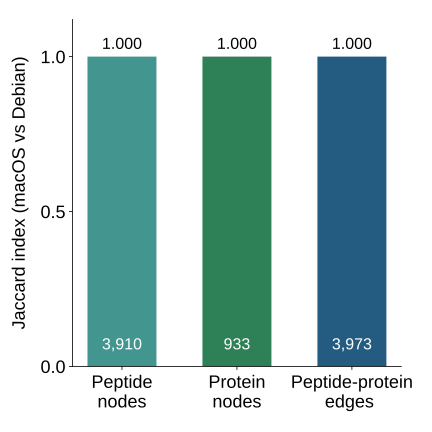

In [10]:
shared = identification_shared
unions = identification_unions
jaccard = shared / unions

fig2f, ax = plt.subplots(figsize=(6, 6))
ax.bar(range(3), jaccard, width=0.6, color=["#43958f", "#2e8057", "#245b80"])
for i, (value, count) in enumerate(zip(jaccard, shared)):
    ax.text(i, value + 0.025, f"{value:.3f}", ha="center", fontsize=16)
    ax.text(i, 0.055, f"{count:,}", ha="center", color="white", fontsize=16)
ax.set(ylim=(0, 1.12), yticks=[0, 0.5, 1], ylabel="Jaccard index (macOS vs Debian)")
ax.set_xticks(range(3), ["Peptide\nnodes", "Protein\nnodes", "Peptide-protein\n edges"])
fig2f.tight_layout()
ax.yaxis.labelpad = 12

fig2f.savefig("fig2f.svg")
plt.show()

### Figure 2g: protein identification q-values


In [11]:
q = pd.concat([
    mdata_mac.mod["protein"].var["q_value"].rename("macOS"),
    mdata_deb.mod["protein"].var["q_value"].rename("Debian"),
], axis=1, join="inner").dropna()

protein_q_values = -np.log10(q.clip(lower=np.finfo(float).tiny)).to_numpy()
protein_q_values = np.asarray(protein_q_values, dtype=float)

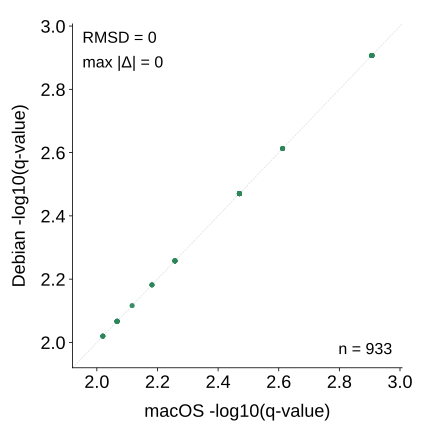

In [12]:
values = protein_q_values
delta = values[:, 1] - values[:, 0]

pad = max(float(np.ptp(values)) * 0.05, 0.1)
limits = [float(values.min()) - pad, float(values.max()) + pad]

fig2g, ax = plt.subplots(figsize=(6, 6))
ax.plot(limits, limits, "--", color="#d3dbe0", lw=0.6, zorder=0)
ax.scatter(values[:, 0], values[:, 1], s=24, color="#2e865b", alpha=0.6, linewidths=0)
ax.set(xlim=limits, ylim=limits, xlabel="macOS -log10(q-value)", ylabel="Debian -log10(q-value)")
ax.text(0.03, 1,
        f"RMSD = {np.sqrt(np.mean(delta**2)):.2g}\n"
        f"max |Δ| = {np.abs(delta).max():.2g}\n",
        transform=ax.transAxes, va="top", fontsize=16, linespacing=1.75)
ax.text(0.97, 0.03, f"n = {len(values):,}", transform=ax.transAxes, va="bottom", ha="right", fontsize=16)
fig2g.tight_layout()
ax.xaxis.labelpad = 12
ax.yaxis.labelpad = 12

fig2g.savefig("fig2g.svg")
plt.show()

### Figure 2h: observed protein intensities


In [13]:
left = mdata_mac.mod["protein"].to_df()
right = mdata_deb.mod["protein"].to_df()

samples = left.index.intersection(right.index, sort=False)
proteins = left.columns.intersection(right.columns, sort=False)
x = left.loc[samples, proteins].to_numpy().ravel()
y = right.loc[samples, proteins].to_numpy().ravel()

observed = np.isfinite(x) & np.isfinite(y)
missing_mismatch = np.count_nonzero(np.isnan(x) != np.isnan(y))
protein_intensities = np.asarray(np.column_stack([x[observed], y[observed]]), dtype=float)

In [14]:
values = protein_intensities
delta = values[:, 1] - values[:, 0]

pad = max(float(np.ptp(values)) * 0.05, 0.1)
limits = [float(values.min()) - pad, float(values.max()) + pad]

fig2h, ax = plt.subplots(figsize=(6, 6))
ax.plot(limits, limits, "--", color="#d3dbe0", lw=0.6, zorder=0)
ax.scatter(values[:, 0], values[:, 1], s=24, color="#2e865b", alpha=0.6, linewidths=0)
ax.set(xlim=limits, ylim=limits, xlabel="macOS log2(intensity)", ylabel="Debian log2(intensity)")
ax.text(0.03, 1,
        f"RMSD = {np.sqrt(np.mean(delta**2)):.2g}\n"
        f"max |Δ| = {np.abs(delta).max():.2g}\n",
        transform=ax.transAxes, va="top", fontsize=16, linespacing=1.75)
ax.text(0.97, 0.03, f"n = {len(values):,}", transform=ax.transAxes, va="bottom", ha="right", fontsize=16)
fig2h.tight_layout()
ax.xaxis.labelpad = 12
ax.yaxis.labelpad = 12

fig2h.savefig("fig2h.svg")
plt.show()

### Figure 2i: differential expressions


In [15]:
de_settings = dict(modality="protein", category="factor value[condition]",
                   ctrl="C10", expr="SVEC", stat_method="limma", p_adjust="bh",
                   min_pct=0.0, log_transformed=True, layer=None)

de_mac = mm.tl.run_de(mdata_mac, **de_settings)
de_deb = mm.tl.run_de(mdata_deb, **de_settings)

q_mac = pd.Series(de_mac.q_value, index=de_mac.features, name="macOS")
q_deb = pd.Series(de_deb.q_value, index=de_deb.features, name="Debian")

q_pairs = pd.concat([q_mac, q_deb], axis=1, join="inner").dropna()
de_q_values = -np.log10(q_pairs.clip(lower=np.finfo(float).tiny)).to_numpy()
de_q_values = np.asarray(de_q_values, dtype=float)

de_thresholds = np.array([0.10, 0.05, 0.01])
de_shared, de_unions = [], []
for threshold in de_thresholds:
    called_mac = set(q_mac.index[q_mac < threshold])
    called_deb = set(q_deb.index[q_deb < threshold])
    de_shared.append(len(called_mac & called_deb))
    de_unions.append(len(called_mac | called_deb))
de_shared, de_unions = np.array(de_shared), np.array(de_unions)

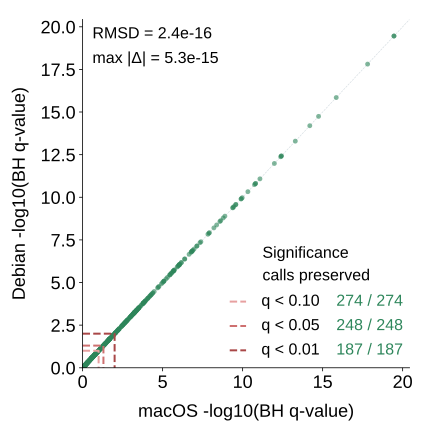

In [16]:
values = de_q_values
delta = values[:, 1] - values[:, 0]

pad = max(float(np.ptp(values)) * 0.05, 0.1)
limits = [float(values.min()) - pad, float(values.max()) + pad]

fig2i, ax = plt.subplots(figsize=(6, 6))
ax.plot(limits, limits, "--", color="#d3dbe0", lw=0.6, zorder=0)
ax.scatter(values[:, 0], values[:, 1], s=24, color="#2e865b", alpha=0.6, linewidths=0)
ax.set(xlim=limits, ylim=limits, xlabel="macOS -log10(BH q-value)", ylabel="Debian -log10(BH q-value)")
ax.set_xlim(left=0)
ax.set_ylim(bottom=0)
ax.text(0.03, 1,
        f"RMSD = {np.sqrt(np.mean(delta**2)):.2g}\n"
        f"max |Δ| = {np.abs(delta).max():.2g}\n",
        transform=ax.transAxes, va="top", fontsize=16, linespacing=1.75)
significance_label = "Significance\ncalls preserved" if np.array_equal(de_shared, de_unions) else "Significance\ncalls differ"
ax.text(0.55, 0.36, significance_label, transform=ax.transAxes, va="top", ha="left", fontsize=16, linespacing=1.5)

for i, (threshold, color) in enumerate(zip(de_thresholds, ["#e7a0a0", "#ce7070", "#a94747"])):
    cutoff = -np.log10(threshold)
    ax.plot([0, cutoff, cutoff], [cutoff, cutoff, 0], "--", color=color, lw=2)
    legend_y = 0.19 - i * 0.07
    ax.plot([0.45, 0.5], [legend_y, legend_y], "--", color=color, lw=2,
            transform=ax.transAxes)
    ax.text(0.725, legend_y, f"q < {threshold:.2f}",
            transform=ax.transAxes, va="center", ha="right", fontsize=16)
    ax.text(0.98, legend_y, f"{de_shared[i]:,} / {de_unions[i]:,}",
            transform=ax.transAxes, va="center", ha="right", fontsize=16, color="#2e865b")
fig2i.tight_layout()
ax.xaxis.labelpad = 12
ax.yaxis.labelpad = 12

fig2i.savefig("fig2i.svg")
plt.show()

## Multi-omics analysis


In [17]:
set_matplotlib_formats("svg", bbox_inches="tight")
plt.rcdefaults()
plt.rcParams["font.family"] = "Arial"
plt.rcParams["font.size"] = 12
plt.rcParams["svg.fonttype"] = "none"


### Figure 2k: cell conditions and Hmgb2 expression


In [18]:
mdata = mm.read_h5mu("Fulcher_multimodal.h5mu")


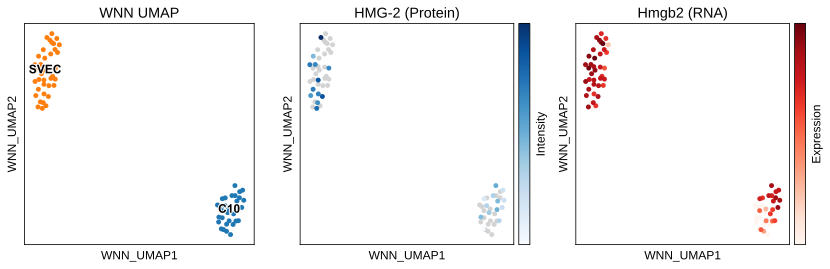

In [19]:
fig, (ax0, ax1, ax2) = plt.subplots(1, 3, figsize=(14, 4))
mu.pl.embedding(mdata, basis="WNN_UMAP", color="factor value[condition]", size=100, title="WNN UMAP", ax=ax0, legend_loc="on data", legend_fontoutline=2, show=False)
mu.pl.embedding(mdata, basis="WNN_UMAP", color="P30681", size=100, ax=ax1, title="HMG-2 (Protein)", colorbar_loc=None, show=False, cmap="Blues")
mu.pl.embedding(mdata, basis="WNN_UMAP", color="Hmgb2", size=100, ax=ax2, title="Hmgb2 (RNA)", colorbar_loc=None, show=False, cmap="Reds")

fig.colorbar(mappable=ax1.collections[0], ax=ax1, fraction=0.05, aspect=20, pad=0.02, anchor=(1, 0))
fig.colorbar(mappable=ax2.collections[0], ax=ax2, fraction=0.05, aspect=20, pad=0.02, anchor=(1, 0))

ax1.collections[0].colorbar.set_label("Intensity", rotation=90, ha="center", va="top", x=0.5, y=0.5, size=12, labelpad=6)
ax2.collections[0].colorbar.set_label("Expression", rotation=90, ha="center", va="top", x=0.5, y=0.5, size=12, labelpad=6)

ax0.xaxis.labelpad = 6
ax0.yaxis.labelpad = 6
for ax in (ax1, ax2):
    cbar = ax.collections[0].colorbar
    cbar.set_ticks([])
    cbar.minorticks_off()
    ax.xaxis.labelpad = 6
    ax.yaxis.labelpad = 6


fig.savefig("fig2k.svg", dpi=300, bbox_inches="tight")

### Figure 2l: variance explained by each factor


In [20]:
model = mofa.mofa_model("MOFA_model.hdf5")


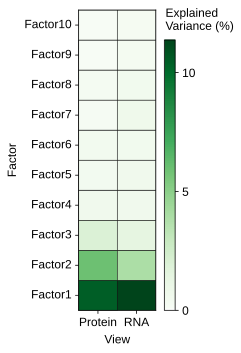

In [21]:
r2 = model.get_variance_explained(views=["protein", "rna"])

r2["View"] = r2["View"].map({"protein": "Protein", "rna": "RNA"})
r2["Factor"] = pd.Categorical(
    r2["Factor"],
    categories=[f"Factor{i+1}" for i in range(r2["Factor"].nunique())],
    ordered=True,
)
r2_mat = r2.pivot_table(index="Factor", columns="View", values="R2")

# Plot
fig = plt.figure(figsize=(3.5, 5))
ax = sns.heatmap(
    r2_mat,
    cmap="Greens",
    linecolor="black",
    linewidth=0.5,
    fmt=".2f",
    cbar_kws=dict(shrink=0.9, anchor=(1, 0), aspect=25, pad=0.05, fraction=0.15),
)

ax.collections[0].colorbar.set_label(
    "Explained\nVariance (%)",
    rotation=0,
    ha="left",
    va="bottom",
    x=0,
    y=1.025,
    labelpad=-30,
)
ax.invert_yaxis()

for spine in ax.spines.values():
    spine.set_edgecolor("black")
    spine.set_linewidth(0.75)
    spine.set_visible(True)

cbar = ax.collections[0].colorbar
cbar.set_ticks([0, 5, 10])

for spine in cbar.ax.spines.values():
    spine.set_edgecolor("black")
    spine.set_linewidth(0.75)

fig.tight_layout()
ax.xaxis.labelpad = 6
ax.yaxis.labelpad = 6
fig.show()

fig.savefig("fig2l.svg", bbox_inches="tight")

### Figure 2m: leading features of Factor 1

Protein labels are retrieved from UniProt when this section is run.


In [22]:
def fetch_protein_label(accession):
    response = requests.get(
        f"https://rest.uniprot.org/uniprotkb/{accession}.json",
        params={"fields": "gene_primary"},
        timeout=30,
    )
    response.raise_for_status()
    for gene in response.json().get("genes", []):
        name = gene.get("geneName", {}).get("value")
        if name:
            return name.upper()
    return accession

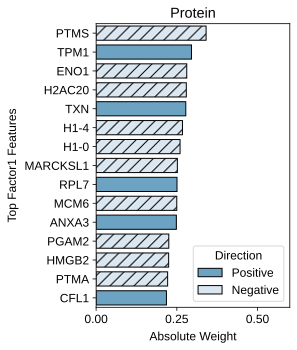

In [23]:
df_factor_prot = model.get_weights(views="protein", factors=0, df=True)
df_factor_prot = pd.melt(
    df_factor_prot.reset_index().rename(columns={"index": "feature"}),
    id_vars="feature",
    var_name="factor",
    value_name="value",
)
df_factor_prot["abs_value"] = abs(df_factor_prot.value)
df_factor_prot["sign"] = df_factor_prot["value"].apply(lambda x: "Positive" if x >= 0 else "Negative")
df_factor_prot["sign"] = pd.Categorical(df_factor_prot["sign"], categories=["Positive", "Negative"], ordered=True)

# Assign ranks to features, per factor
df_factor_prot["abs_rank"] = df_factor_prot.groupby("factor")["abs_value"].rank(ascending=False)
df_factor_prot = df_factor_prot.sort_values(["factor", "abs_rank"], ascending=True)
df_factor_prot = df_factor_prot[df_factor_prot["abs_rank"] <= 15]
df_factor_prot["gene"] = df_factor_prot["feature"].apply(lambda feature: fetch_protein_label(feature.split(",")[0]))

fig = plt.figure(figsize=(4.25, 5))
ax = sns.barplot(
    data=df_factor_prot,
    x="abs_value",
    y="gene",
    hue="sign",
    dodge=False,
    palette={"Positive": "#5DA5D1", "Negative": "#D6E6F4"},
    width=0.75,
    edgecolor="black",
)

for container, hatch in zip(ax.containers, ["", "//"]):
    for bar in container:
        bar.set_hatch(hatch)

ax.set_title("Protein")
ax.set(xlim=[0, 0.6])
ax.xaxis.set_ticks([0, 0.25, 0.5])
ax.set_xlabel("Absolute Weight", size=12)
ax.set_ylabel("Top Factor1 Features", size=12)
ax.legend(title="Direction")

fig.tight_layout()
ax.xaxis.labelpad = 6
ax.yaxis.labelpad = 6
fig.savefig("fig2m_prot.svg", bbox_inches="tight")

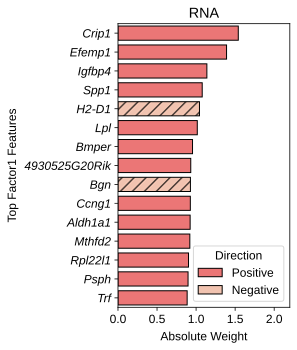

In [24]:
df_f2 = model.get_weights(
    views="rna",
    factors=0,
    df=True,
)
df_f2 = pd.melt(
    df_f2.reset_index().rename(columns={"index": "feature"}),
    id_vars="feature",
    var_name="factor",
    value_name="value",
)
df_f2["abs_value"] = abs(df_f2.value)
df_f2["sign"] = df_f2["value"].apply(lambda x: "Positive" if x >= 0 else "Negative")
df_f2["sign"] = pd.Categorical(df_f2["sign"], categories=["Positive", "Negative"], ordered=True)

# Assign ranks to features, per factor
df_f2["abs_rank"] = df_f2.groupby("factor")["abs_value"].rank(ascending=False)
df_f2 = df_f2.sort_values(["factor", "abs_rank"], ascending=True)
df_f2 = df_f2[df_f2["abs_rank"] <= 15]

fig = plt.figure(figsize=(4.25, 5))
ax = sns.barplot(
    data=df_f2,
    x="abs_value",
    y="feature",
    hue="sign",
    dodge=False,
    palette={"Positive": "#FF6262", "Negative": "#FCBEA5"},
    width=0.75,
    edgecolor="black",
)

for container, hatch in zip(ax.containers, ["", "//"]):
    for bar in container:
        bar.set_hatch(hatch)

ax.set_title("RNA")
ax.set(xlim=[0, 2.2])
ax.xaxis.set_ticks([0.0, 0.5, 1.0, 1.5, 2.0])
ax.set_xlabel("Absolute Weight", size=12)
ax.set_ylabel("Top Factor1 Features", size=12)
for tick in ax.get_yticklabels():
    tick.set_fontstyle("italic")
ax.legend(title="Direction")

fig.tight_layout()
ax.xaxis.labelpad = 6
ax.yaxis.labelpad = 6
fig.savefig("fig2m_rna.svg", bbox_inches="tight")

model.close()
